# Comparison with dipole excitation published by Kimble *et al.*

In this Jupiter notebook we are going to compare how our code can compute the coupling constant between the photonic crystal and a present quantum emitter. We compare the excitation the emitter creates on the crystal and compare it with the excitation created by a dipole shown in [this article](https://doi.org/10.1073/pnas.1822110116).

In [1]:
import numpy as np

import meep as mp
from meep import mpb

import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.colors as colors

import my_functions as mf

# ...
import pythtb as tb

Just a bit of code to make figures more beautiful

In [3]:
mpl.rcParams.update({
    # Figure
    "figure.figsize": (4.5, 3.5),   # default figure size in inches
    "figure.dpi": 150,              # higher resolution

    # Font
    "font.family": "serif",         # switch to serif (journal-style)
    "font.size": 11,                # base font size
    "mathtext.fontset": "stix",     # match math to Times-like font

    # Axes
    "axes.labelsize": 11,           # axis label font size
    "axes.titlesize": 12,           # title font size
    "axes.linewidth": 1,            # thickness of axes spines

    # Ticks
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,

    # Tick length/width
    "xtick.major.size": 4,
    "xtick.major.width": 1,
    "ytick.major.size": 4,
    "ytick.major.width": 1,

    # Grid (off by default, but can be enabled)
    "grid.alpha": 0.3,
    "grid.linestyle": "--",

    # Legend
    "legend.fontsize": 10,
    "legend.frameon": False,
})

## Set-up the model for the numerical simulation

In [4]:
# INPUTS --------------------------------------------------------------------------------- #
bands = [1]

epsilon_input_file = "data/python_server-epsilon.h5"

tolerance = 1e-7

# Positions of the quantum emitters in units of the lattice constant 'a'
r0_list = [
    [0.00, 0.00, 0.0],
    [-1.00, 0.00, 0.0],
    [0.00, -1.00, 0.0],
    [1.00, 0.00, 0.0],
    [0.00, 1.00, 0.0],
    [-0.50, -0.50, 0.0],
    [0.50, -0.50, 0.0],
    [0.50, 0.50, 0.0],
    [-0.50, 0.50, 0.0],
    [-0.50, 0.00, 0.0],
    [0.50, 0.00, 0.0],
    [0.00, 0.50, 0.0],
    [-0.50, 0.00, 0.0],
]

# ---------------------------------------------------------------------------------------- #

# Read some data from the epsilon.h5 file
d = mf.read_epsilon_file(epsilon_input_file)
resolution = d["resolution"]
lattice_vecs = d["lattice vectors"]
lattice_size = d["lattice size"]

# Prepare list of k-points via Monkhorst-Pack sampling
# .. define number of points per direction for the Monkhorst-Pack grid
Nk = 64
# .. get the reciprocal lattice vectors
b1, b2, b3 = mf.find_reciprocal_lattice_vectors(lattice_vecs, twopi=False)
# .. obtain the list of k-points
k_points_array = mf.MonkhorstPack(Nk, b1, b2, coordinates="lattice")

# Print summary of parameters
print("\n")
print("bands                = " + str(bands))
print("epsilon_input_file   = " + '"' + epsilon_input_file + '"')
print("resolution           = " + str(resolution))
print("lattice size         = " + str(lattice_size))
print("lattice vectors      = " + str(lattice_vecs))
print("tolerance            = " + str(tolerance))



bands                = [1]
epsilon_input_file   = "data/python_server-epsilon.h5"
resolution           = [64, 64, 1]
lattice size         = [np.float64(1.0), np.float64(1.0), 0]
lattice vectors      = [[1.0, 0.0, 0.0], [0.0, 1.0, 0.0], [0.0, 0.0, 1.0]]
tolerance            = 1e-07


## Compute the fields of the photonic crystal

The fields are stored in the folder "/data/Nk64". You may skip this computation if they are already computed and load them afterwards.

In [201]:
# PREPARE THE DATA TO THE MPB SIMULATION ...
# ...
geometry_lattice = mp.Lattice(
    size=lattice_size, basis1=lattice_vecs[0], basis2=lattice_vecs[1]
)

# ...
ms = mpb.ModeSolver(
    num_bands=max(bands),
    resolution=mp.Vector3(*resolution),
    epsilon_input_file=epsilon_input_file,
    tolerance=tolerance,
    mesh_size=1,
    geometry_lattice=geometry_lattice,
    k_points=mf.array_to_Vector3(k_points_array),
)

# Map k_points into the first Brillouin zone
ms.k_points = list(map(ms.first_brillouin_zone, ms.k_points))

In [4]:
# CALCULATION OF THE FIELDS BY MPB ...

# Define the band function to be pass to MPB
fields_MPBarr = []


def get_efields(ms, band):
    # ..
    ms.get_efield(band, bloch_phase=False)
    # ..
    for r0 in r0_list:
        fields_MPBarr.append(
            ms.get_bloch_field_point(mp.Vector3(*r0))
        )  # NOTE: this returns the Bloch periodic functions


# Run the MPB simulation
ms.run_te(
    mpb.fix_hfield_phase, get_efields
)  # NOTE: we need to fix the phase of the fields we are computing

Initializing eigensolver data
Computing 1 bands with 1e-07 tolerance
Working in 2 dimensions.
Grid size is 64 x 64 x 1.
Solving for 1 bands at a time.
Creating Maxwell data...
Mesh size is 1.
Lattice vectors:
     (1, 0, 0)
     (0, 1, 0)
     (0, 0, 1)
Cell volume = 1
Reciprocal lattice vectors (/ 2 pi):
     (1, -0, 0)
     (-0, 1, -0)
     (0, -0, 1)
Geometric objects:
Geometric object tree has depth 1 and 0 object nodes (vs. 0 actual objects)
read in 64x64x1 epsilon-input-file "data/python_server-epsilon.h5"
Initializing epsilon function...
Allocating fields...
Solving for band polarization: te.
Initializing fields to random numbers...
4096 k-points
  Vector3<-0.4921875, -0.4921875, 0.0>
  Vector3<-0.4921875, -0.4765625, 0.0>
  Vector3<-0.4921875, -0.4609375, 0.0>
  Vector3<-0.4921875, -0.4453125, 0.0>
  Vector3<-0.4921875, -0.4296875, 0.0>
  Vector3<-0.4921875, -0.4140625, 0.0>
  Vector3<-0.4921875, -0.3984375, 0.0>
  Vector3<-0.4921875, -0.3828125, 0.0>
  Vector3<-0.4921875, -0.3

In [5]:
# MANIPULATE THE DATA FROM THE MPB RUN ...

# .. Define inputs
fields_in = np.array(fields_MPBarr)
kpts_in = np.array(ms.k_points)
r0pts_in = np.array(r0_list)
freqs_in = np.array(ms.all_freqs)

# .. Re-arrange the input data
d = mf.arrange_data(fields_in, kpts_in, r0pts_in, freqs_in, lattice_vecs)

# .. Define outputs
freqs = d["frequencies"]
Ex = d["Ex"]
Ey = d["Ey"]
Ez = d["Ez"]

kpts = d["kpts-cartesian"]
r0pts = d["r0pts-cartesian"]

# ...
args = {"freqs":freqs, "Ex":Ex, "Ey":Ey, "Ez":Ey, "kpts":kpts, "r0pts":r0pts}

filename = "MPB_output.pkl"
folder = "./data/Nk64"

mf.save(args, filename, folder)

## Define the tight-binding model of the crystal

In [9]:
lat = [[1, 0], [0, 1]]
orb = [[0, 0]]

band_index = 0  # index of the band to plot (0-based)

alpha = 0.067861
t1 = -0.017145
t2 = 0.00017919

alpha_norm = alpha/np.abs(t1)
t1_norm = t1/np.abs(t1)
t2_norm = t2/np.abs(t1)

infiniteModel = tb.tb_model(2, 2, lat, orb)

# onsite term
infiniteModel.set_onsite([alpha_norm])

# 1st nn
infiniteModel.set_hop(t1_norm, 0, 0, [1, 0])
infiniteModel.set_hop(t1_norm, 0, 0, [0, 1])

# 2nd nn
infiniteModel.set_hop(t2_norm, 0, 0, [1, 1])
infiniteModel.set_hop(t2_norm, 0, 0, [1, -1])

In [10]:
# %% Compute bands for the infinite model

### Compute bands along high-symmetry path ...
# define the High-Symmetry Points (HSPs)
path = [[0, 0], [0, 0.5], [0.5, 0.5], [0, 0]]

# creates a path between the HSPs defined before with 500 points between them
k_vec, k_dist, k_node = infiniteModel.k_path(path, 500, report=False)

# define HSPs labels
k_label = [r"$\Gamma$", r"X", r"M", r"$\Gamma$"]

# solve the infinite model in the considered path
evals = infiniteModel.solve_all(k_vec)

### Compute bands in the whole 1st Brillouin zone ....
k_pts = infiniteModel.k_uniform_mesh([200, 200])

# solve infinite model in kpoints mesh
mesh_evals = infiniteModel.solve_all(k_pts).flatten()

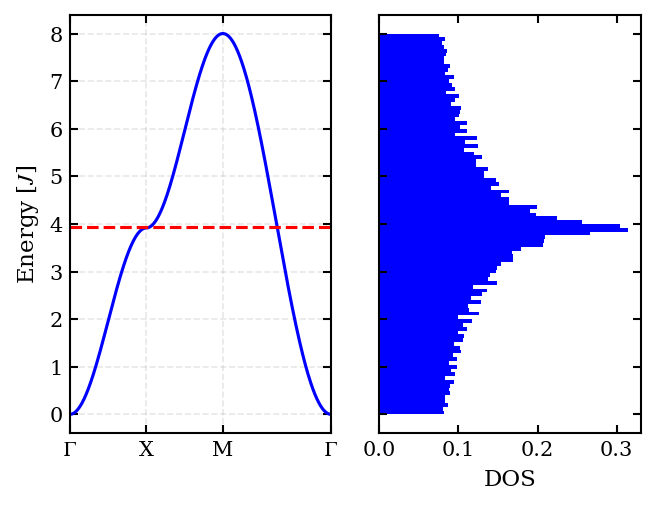

In [12]:
# %% Plot the bands of the infinite model

fig, ax = plt.subplots(1, 2, sharey=True)

# plot bands ...
for n in range(infiniteModel._norb):
    ax[0].plot(k_dist, evals[n], color="b")
# ...
ax[0].set_xlim(k_node[0], k_node[-1])
ax[0].set_xticks(k_node)
ax[0].set_xticklabels(k_label)
ax[0].grid()
ax[0].set_ylabel(r"Energy [$J$]")

# select the emitters detunings, we are picking the value of the frequency at the X point
detuning_freq = evals[band_index][k_node[1] == k_dist].item() + 0.01 # add small detuning

# save it for later use
mf.save(detuning_freq, "detuning_freq.pkl", "./data")

# add line for the emitter's frequency
ax[0].axhline(y=detuning_freq, color="r", linestyle="dashed")

# plot density of states ...
ax[1].hist(mesh_evals, 100, density=True, orientation="horizontal", color="b")
# ...
ax[1].set_xlabel("DOS")

fig.tight_layout()
fig.savefig("./figures/bands_DOS_tb.svg", dpi=300)

## Compute the light-matter coupling 

In [5]:
# PERFORM THE FOURIER TRANSFORMATION OF THE COUPLING FUNCTION ...

# load the data from a file
data = mf.load("./data/Nk64/MPB_output.pkl")
Ex = data["Ex"]
Ey = data["Ey"]
Ez = data["Ez"]
kpts = data["kpts"]
r0pts = data["r0pts"]

# .. Select the dipole moment
theta = (135) * np.pi / 180  # 90 or 135
dipole_moment = np.array([np.cos(theta), np.sin(theta), 0])

# .. Define the fields of the selected band
E_band = [Ex[band_index, :, :], Ey[band_index, :, :], Ez[band_index, :, :]]

# Compute g(r0,r) for r a continuous set of points, this will interpolate the values, but
# will give a good idea of the spatial profile of g(r0,r)
xg = np.linspace(-5, 5, 101)
yg = np.linspace(-5, 5, 101)
rpts = mf.meshgrid_points(xg, yg)

gr0r = mf.compute_gr0r(E_band, dipole_moment, detuning_freq, kpts, rpts)

NameError: name 'band_index' is not defined

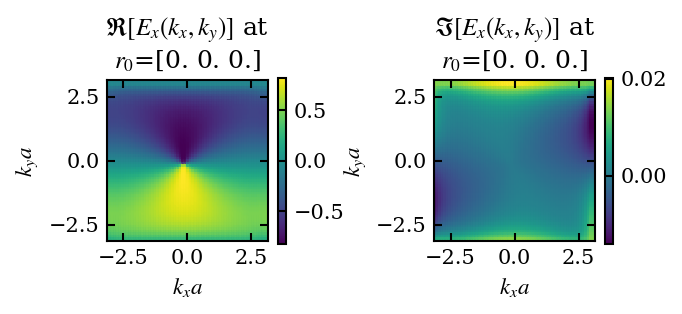

In [41]:
# PLOT FIELDS IN RECIPROCAL SPACE ...

# Select the position of the emitter in the unit cell r0 = r0pts(emitter_indx)
emitter_indx = 0

# ...
x = kpts[:, 0]
y = kpts[:, 1]
z1 = np.real(E_band[0][:, emitter_indx])
z2 = np.imag(E_band[0][:, emitter_indx])

# Define the marker size as a function of n, i.e., the number of points to scatter
marker_size = lambda n: 2.1e5 / (np.log(np.sqrt(n)) * n)

# ...
fig, axs = plt.subplots(1, 2)

sc1 = axs[0].scatter(x, y, c=z1, marker="s", s=marker_size(len(x)))
sc2 = axs[1].scatter(x, y, c=z2, marker="s", s=marker_size(len(x)))

fig.colorbar(sc1, ax=axs[0], shrink=0.35)
fig.colorbar(sc2, ax=axs[1], shrink=0.35)

axs[0].set_title(r"$\Re[E_x(k_x,k_y)]$ at" + "\n" + r"$r_0$=" + str(r0pts[emitter_indx]))
axs[0].set(xlabel=r"$k_xa$", ylabel=r"$k_ya$")
axs[0].set_xlim([-np.pi, np.pi])
axs[0].set_ylim([-np.pi, np.pi])
axs[0].set_aspect("equal")

axs[1].set_title(r"$\Im[E_x(k_x,k_y)]$ at" + "\n" + r"$r_0$=" + str(r0pts[emitter_indx]))
axs[1].set(xlabel=r"$k_xa$", ylabel=r"$k_ya$")
axs[1].set_xlim([-np.pi, np.pi])
axs[1].set_ylim([-np.pi, np.pi])
axs[1].set_aspect("equal")

fig.tight_layout()
fig.savefig("./figures/fields_kspace_tb.svg", dpi=300)

real part range: 1 .. 4


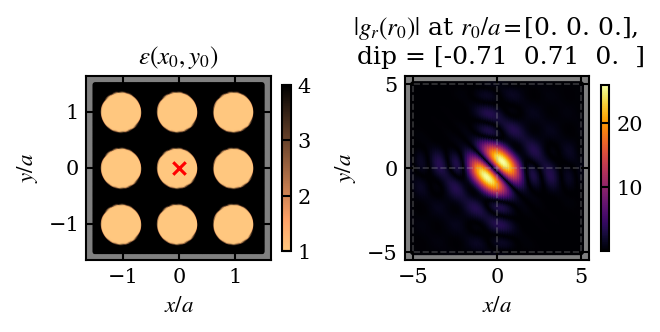

In [42]:
# PLOT COUPLING FUNCTION g(r0,r) IN REAL SPACE (in continous coordinate r) ...

# ...
md = mpb.MPBData(rectify=False, periods=3)

d = mf.convert_epsilon("./data/python_server-epsilon.h5", md)
x1 = d["positions-cartesian"][:, 0]
y1 = d["positions-cartesian"][:, 1]
z1 = d["epsilon values"]

x2 = rpts[:, 0]
y2 = rpts[:, 1]
z2 = np.abs(gr0r[emitter_indx, :])

# Define the marker size as a function of n, i.e., the number of points to scatter
marker_size = lambda n: 2e5 / (np.log(np.sqrt(n)) * n)

# ...
fig, axs = plt.subplots(1, 2)

sc1 = axs[0].scatter(x1, y1, c=z1, s=marker_size(len(x1)), marker="o", cmap="copper_r")
sc1_cross = axs[0].scatter(
    r0pts[emitter_indx, 0], r0pts[emitter_indx, 1], marker="x", color="r"
)

sc2 = axs[1].scatter(
    x2,
    y2,
    c=z2,
    s=marker_size(len(x2)),
    marker="o",
    cmap="inferno",
    norm=colors.Normalize(),
)

# colorbar
fig.colorbar(sc1, ax=axs[0], shrink=0.35)
fig.colorbar(sc2, ax=axs[1], shrink=0.35)

# axes properties
axs[0].set_title(r"$\epsilon(x_0,y_0)$")
axs[0].set(xlabel=r"$x/a$", ylabel=r"$y/a$")
axs[0].set_aspect("equal")
axs[0].set_facecolor("gray")

axs[1].set_title(
    r"$|g_r(r_0)|$ at $r_0/a=$"
    + str(r0pts[emitter_indx, :])
    + ", \n dip = "
    + str(np.round(dipole_moment, 2))
)  # NOTE: use r-string for introducing latex with matplotlib
axs[1].set(xlabel=r"$x/a$", ylabel=r"$y/a$")
axs[1].set_aspect("equal")
axs[1].grid()
axs[1].set_facecolor("gray")

fig.tight_layout()
fig.savefig("./figures/gr0r_continuous_tb.svg", dpi=300)

In [ ]:
# Compute g(r0,rj) for rj a discrete set of points (lattice sites)
xjg = np.arange(-Nk//2, Nk//2 + 1, 1)
yjg = np.arange(-Nk//2, Nk//2 + 1, 1)
rjpts = mf.meshgrid_points(xjg, yjg)

gr0rj = mf.compute_gr0r(E_band, dipole_moment, detuning_freq, kpts, rjpts)

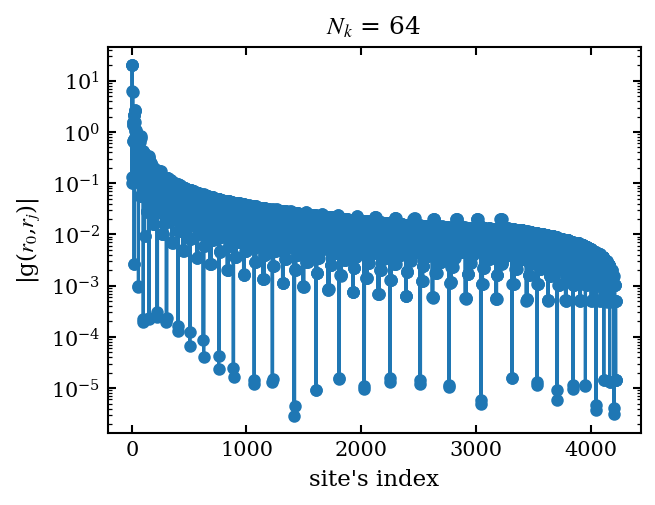

In [ ]:
# PLOT COUPLING FUNCTION g(r0,rj) IN REAL SPACE (in discrete sites rj) ...

# ...
# Get distance of the rj points to the origin
distance_to_center = np.linalg.norm(rjpts, axis=1)
# Get the ordering of the rj points as a fucntion of their distance to the origin
indxs_sorted_by_distance = np.argsort(distance_to_center)

# print(distance_to_center[indxs_sorted_by_distance].reshape(-1,1))
# print(rjpts[indxs_sorted_by_distance,:])

# Define the function to be plotted
y = np.abs(gr0rj[emitter_indx, indxs_sorted_by_distance])

# ...
fig, ax = plt.subplots()

ax.plot(y, marker="o", markersize=5)

# axes properties
ax.set_title("$N_k$ = " + str(int(np.sqrt(len(kpts)))))
ax.set(xlabel="site" "'" "s index", ylabel="|g($r_0$,$r_j$)|")
ax.set_yscale("log")

fig.tight_layout()
fig.savefig("./figures/gr0rj_tb.svg", dpi=300)

## Compute the system dynamics

In [30]:
# %% Finite model definition
N_cells = 41

# Cut the system
temporalModel = infiniteModel.cut_piece(
    N_cells, fin_dir=0, glue_edgs=False
)  # cutout along 1st direction
finiteModel = temporalModel.cut_piece(
    N_cells, fin_dir=1, glue_edgs=False
)  # cutout along 2nd direction

In [31]:
# Let me recalculate the coupling accordingly with the system's size (N_cells = 41).
# NOTE: the indexing is now "xy" so that the ordering of rjpts coincides with the one created by pythonTB

xjg = np.arange(-20,20 + 1, 1)
yjg = np.arange(-20,20 + 1, 1)
rjpts = mf.meshgrid_points(xjg, yjg, indexing="xy")

gr0rj = mf.compute_gr0r(E_band, dipole_moment, detuning_freq, kpts, rjpts)
gr0rj_norm = gr0rj * np.abs(t1)  # normalize to |t1|
# TODO: check normalization here, does it make sense?

In [32]:
# %% Build the light-matter Hamiltonian

# ... non-local couplings
values = gr0rj_norm[band_index, :]
indexes = np.arange(0, len(gr0rj[0, :]), 1)
couplings = [[list(values), list(indexes)]]

# build the light-matter Hamiltonian
H_total = mf.make_light_matter_Hamiltonian(finiteModel, detuning_freq, couplings)

In [33]:
# %% Compute time evolution

from scipy.sparse.linalg import expm_multiply

#
t0 = 0
tf = 20
t_steps = 100 + 1

tvals = np.linspace(t0, tf, t_steps)

# Define initial condition
psi0 = np.zeros(np.shape(H_total)[0])
psi0[0] = 1

# Compute time evolution
psit = expm_multiply(-1j * H_total, psi0, t0, tf, t_steps, endpoint=True)

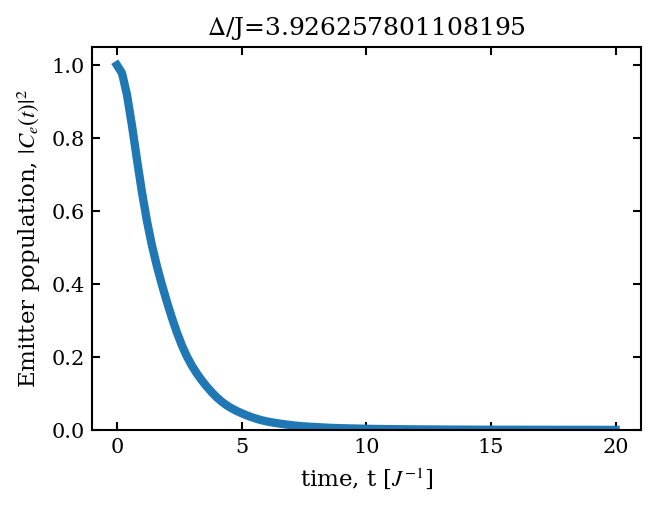

In [34]:
# %% Plot emitter's dynamics

# Prepare data to be plotted ...

# get emitter component of the overall wavefunction
mod_Ce_squared = np.abs(psit[:, 0]) ** 2

# Plot figure ...
fig, ax = plt.subplots()
ax.plot(tvals, mod_Ce_squared, lw=4)

# axis properties
ax.set_xlabel(r"time, t [$J^{-1}$]")
ax.set_ylabel(r"Emitter population, $|C_e(t)|^2$")
ax.set_title(r"$\Delta$/J=" + str(detuning_freq))
ax.set_ylim([0, 1.05])

fig.tight_layout()
fig.savefig("./figures/emitter_dynamics_tb.svg", dpi=300)

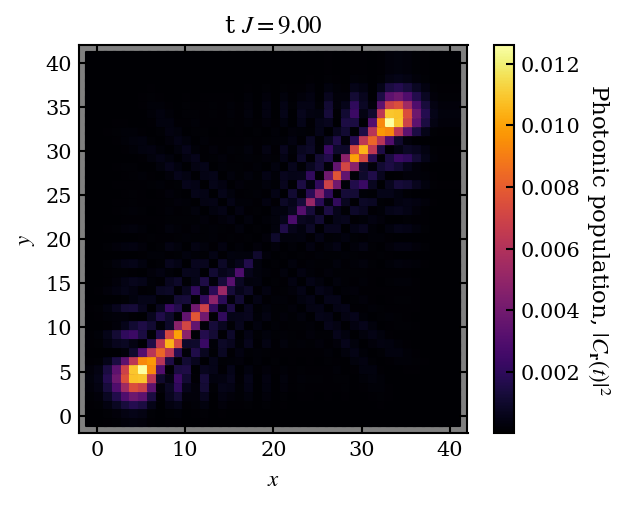

In [37]:
# %% Plot bath dynamics

time_index = 45

# Prepare data to be plotted ...

# get positions in Cartesian coordinates (requires find_positions() defined above)
positions = mf.find_positions(finiteModel._orb, finiteModel._lat)

# get photonic component of the overal wavefunction at selected time, i.e, tvals[time_index]
mod_Cr_squared = np.abs(psit[time_index, 1 : np.shape(psit)[1]]) ** 2

x = positions[:, 0]
y = positions[:, 1]
z = mod_Cr_squared

# Plot figure ...
fig, ax = plt.subplots()

cm = plt.get_cmap("inferno")

# scatter plot
sc = plt.scatter(x, y, c=z, s=100, marker="s", cmap=cm)

# axis properties
ax.set(xlabel=r"$x$", ylabel=r"$y$", title=r"t $J= %.2f$" % tvals[time_index])
ax.set_facecolor("gray")
ax.set_aspect("equal")

# colorbar
cbar = plt.colorbar(sc)
cbar.set_label(r"Photonic population, $|C_\mathbf{r}(t)|^2$", rotation=270, labelpad=15)

fig.tight_layout()
fig.savefig("./figures/bath_dynamics_tb.svg", dpi=300)

## Extra plots for the paper

Maybe consider deleting this section

### Plot the band structure model vs simulation

In [33]:
alpha = 0.07755639
t1 = -0.01993698
t2 = 0.00053966

infiniteModel = tb.tb_model(2, 2, lat, orb)

# onsite term
infiniteModel.set_onsite([alpha])

# 1st nn
infiniteModel.set_hop(t1, 0, 0, [1, 0])
infiniteModel.set_hop(t1, 0, 0, [0, 1])

# 2nd nn
infiniteModel.set_hop(t2, 0, 0, [1, 1])
infiniteModel.set_hop(t2, 0, 0, [1, -1])

In [34]:
# %% Compute bands for the infinite model

### Compute bands along high-symmetry path ...
# define the High-Symmetry Points (HSPs)
path = [[0, 0], [0, 0.5], [0.5, 0.5], [0, 0]]

# creates a path between the HSPs defined before with 500 points between them
k_vec, k_dist, k_node = infiniteModel.k_path(path, 500, report=False)

# define HSPs labels
k_label = [r"$\Gamma$", r"X", r"M", r"$\Gamma$"]

# solve the infinite model in the considered path
evals = infiniteModel.solve_all(k_vec)

In [ ]:
# compute the bands with MPB for comparison

geometry_lattice = mp.Lattice(
    size=lattice_size, basis1=lattice_vecs[0], basis2=lattice_vecs[1]
)

ms = mpb.ModeSolver(
    num_bands=max(bands),
    resolution=mp.Vector3(*resolution),
    epsilon_input_file=epsilon_input_file,
    tolerance=tolerance,
    mesh_size=1,
    geometry_lattice=geometry_lattice,
    k_points=mf.array_to_Vector3(k_vec),
)

ms.run()

# all frequency bands
freqs = ms.all_freqs

Initializing eigensolver data
Computing 1 bands with 1e-07 tolerance
Working in 2 dimensions.
Grid size is 64 x 64 x 1.
Solving for 1 bands at a time.
Creating Maxwell data...
Mesh size is 1.
Lattice vectors:
     (1, 0, 0)
     (0, 1, 0)
     (0, 0, 1)
Cell volume = 1
Reciprocal lattice vectors (/ 2 pi):
     (1, -0, 0)
     (-0, 1, -0)
     (0, -0, 1)
Geometric objects:
Geometric object tree has depth 1 and 0 object nodes (vs. 0 actual objects)
read in 64x64x1 epsilon-input-file "data/python_server-epsilon.h5"
Initializing epsilon function...
Allocating fields...
Solving for band polarization: .
Initializing fields to random numbers...
500 k-points
  Vector3<0.0, 0.0, 0.0>
  Vector3<0.0, 0.003424657534246575, 0.0>
  Vector3<0.0, 0.00684931506849315, 0.0>
  Vector3<0.0, 0.010273972602739725, 0.0>
  Vector3<0.0, 0.0136986301369863, 0.0>
  Vector3<0.0, 0.017123287671232876, 0.0>
  Vector3<0.0, 0.02054794520547945, 0.0>
  Vector3<0.0, 0.023972602739726026, 0.0>
  Vector3<0.0, 0.027397260

/tmp/ipykernel_10919/4189464151.py:5: RuntimeWarning: invalid value encountered in sqrt
  ax.plot(k_dist, np.sqrt(n), color="r", linestyle="--")


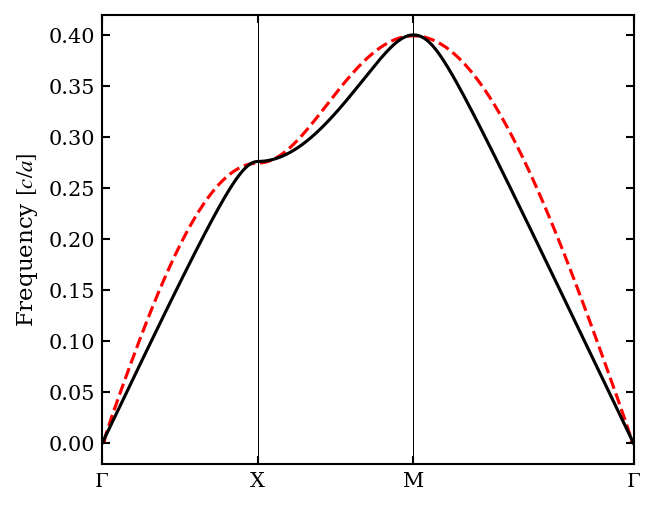

In [41]:
fig, ax = plt.subplots()

# plot bands ...
for n in evals:
    ax.plot(k_dist, np.sqrt(n), color="r", linestyle="--")

ax.plot(k_dist, freqs, color="k")
# ...
ax.set_xlim(k_node[0], k_node[-1])
ax.set_xticks(k_node)
ax.set_xticklabels(k_label)
for n in range(len(k_node)):
    ax.axvline(x=k_node[n], linewidth=0.5, color="k")
# ax[0].set_ylim(-20, 20)
ax.set_ylabel(r"Frequency $[c/a]$")

fig.tight_layout()
fig.savefig("./figures/bands_tb_vs_mpb.png", dpi=300)

### Plot the dielectric structure

real part range: 1 .. 4


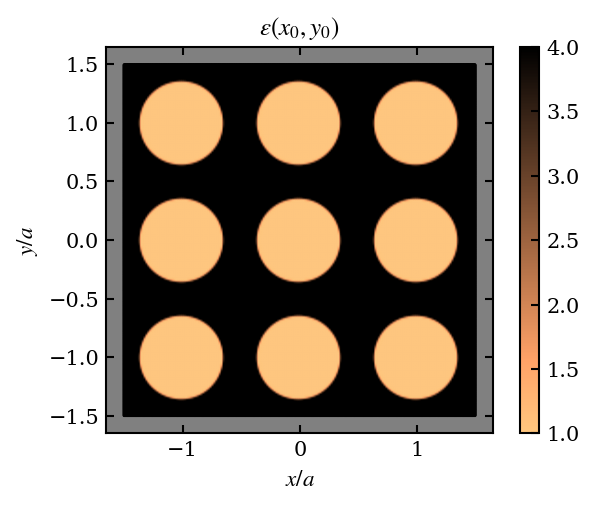

In [311]:
md = mpb.MPBData(rectify=False, periods=3, resolution=300)

d = mf.convert_epsilon("data/python_server-epsilon.h5", md)
x1 = d["positions-cartesian"][:, 0]
y1 = d["positions-cartesian"][:, 1]
z1 = d["epsilon values"]

fig, axs = plt.subplots()

# Define the marker size as a function of n, i.e., the number of points to scatter
marker_size = lambda n: 2e5 / (np.log(np.sqrt(n)) * n)

sc1 = axs.scatter(x1, y1, c=z1, s=marker_size(len(x1)), marker="o", cmap="copper_r")

# colorbar
fig.colorbar(sc1, ax=axs)

# axes properties
axs.set_title(r"$\epsilon(x_0,y_0)$")
axs.set(xlabel=r"$x/a$", ylabel=r"$y/a$")
axs.set_aspect("equal")
axs.set_facecolor("gray")

fig.tight_layout()
fig.savefig("./figures/epsilon.png", dpi=300)

### Coupling constant at different dipole orientations

In [ ]:
# PERFORM THE FOURIER TRANSFORMATION OF THE COUPLING FUNCTION ...

mf.load("./data/Nk64/MPB_output.pkl")

band_index = 0

# .. Select the dipole moment
theta_1 = (90) * np.pi / 180  # 90 or 135
theta_2 = (135) * np.pi / 180  # 90 or 135
dipole_moment_1 = np.array([np.cos(theta_1), np.sin(theta_1), 0])
dipole_moment_2 = np.array([np.cos(theta_2), np.sin(theta_2), 0])

# .. Define the fields of the selected band
E_band = [Ex[band_index, :, :], Ey[band_index, :, :], Ez[band_index, :, :]]

# Compute g(r0,r) for r a continuous set of points, this will interpolate the values, but
# will give a good idea of the spatial profile of g(r0,r)
xg = np.linspace(-5, 5, 101)
yg = np.linspace(-5, 5, 101)
rpts = mf.meshgrid_points(xg, yg)

gr0r_1 = mf.compute_gr0r(E_band, dipole_moment_1, detuning_freq, kpts, rpts)
gr0r_2 = mf.compute_gr0r(E_band, dipole_moment_2, detuning_freq, kpts, rpts)

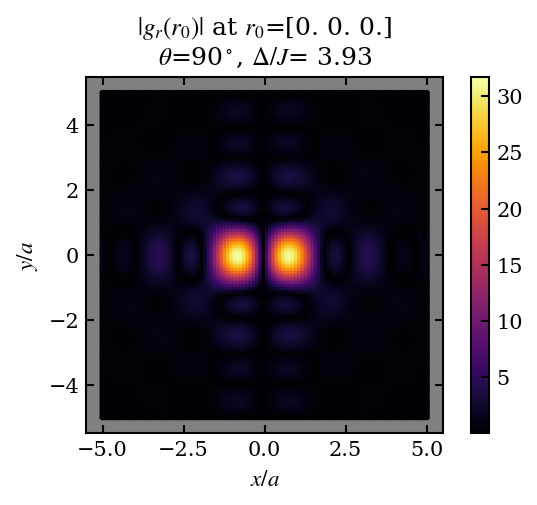

In [ ]:
fig, axs = plt.subplots()

emitter_indx = 0

x2 = rpts[:, 0]
y2 = rpts[:, 1]
z2 = np.abs(gr0r_1[emitter_indx, :])

# Define the marker size as a function of n, i.e., the number of points to scatter
marker_size = lambda n: 2e5 / (np.log(np.sqrt(n)) * n)

sc = axs.scatter(
    x2,
    y2,
    c=z2,
    s=marker_size(len(x2)),
    marker="o",
    cmap="inferno",
    norm=colors.Normalize(),
)

# colorbar
fig.colorbar(sc, ax=axs)

# axes properties
axs.set_title(r"$|g_r(r_0)|$ at $r_0$=" + str(r0pts[emitter_indx]) + "\n" +
              r"$\theta$=" + str(int(theta_1 * 180 / np.pi)) + r"$^\circ$" + r", $\Delta/J$= %.2f" % detuning_freq)
axs.set(xlabel=r"$x/a$", ylabel=r"$y/a$")
axs.set_aspect("equal")
axs.set_facecolor("gray")

fig.tight_layout()
fig.savefig("./figures/gr0r_continuous_tb_90_degrees.png", dpi=300)

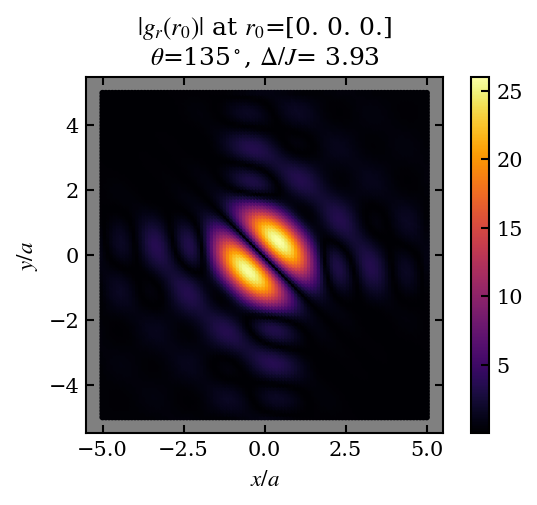

In [ ]:
fig, axs = plt.subplots()

x2 = rpts[:, 0]
y2 = rpts[:, 1]
z2 = np.abs(gr0r_2[emitter_indx, :])

# Define the marker size as a function of n, i.e., the number of points to scatter
marker_size = lambda n: 2e5 / (np.log(np.sqrt(n)) * n)

sc = axs.scatter(
    x2,
    y2,
    c=z2,
    s=marker_size(len(x2)),
    marker="o",
    cmap="inferno",
    norm=colors.Normalize(),
)

# colorbar
fig.colorbar(sc, ax=axs)

# axes properties
axs.set_title(r"$|g_r(r_0)|$ at $r_0$=" + str(r0pts[emitter_indx]) + "\n" +
              r"$\theta$=" + str(int(theta_2 * 180 / np.pi)) + r"$^\circ$" + r", $\Delta/J$= %.2f" % detuning_freq)
axs.set(xlabel=r"$x/a$", ylabel=r"$y/a$")
axs.set_aspect("equal")
axs.set_facecolor("gray")

fig.tight_layout()
fig.savefig("./figures/gr0r_continuous_tb_135_degrees.png", dpi=300)

### Contour plot of the band structure of the tight-binding model

In [42]:
lat = [[1, 0], [0, 1]]
orb = [[0, 0]]

band_index = 0  # index of the band to plot (0-based)

alpha = 0.067861
t1 = -0.017145
t2 = 0.00017919

alpha_norm = alpha/np.abs(t1)
t1_norm = t1/np.abs(t1)
t2_norm = t2/np.abs(t1)

infiniteModel = tb.tb_model(2, 2, lat, orb)

# onsite term
infiniteModel.set_onsite([alpha_norm])

# 1st nn
infiniteModel.set_hop(t1_norm, 0, 0, [1, 0])
infiniteModel.set_hop(t1_norm, 0, 0, [0, 1])

# 2nd nn
infiniteModel.set_hop(t2_norm, 0, 0, [1, 1])
infiniteModel.set_hop(t2_norm, 0, 0, [1, -1])

In [43]:
# --- Parameters ---
nk = 201  # grid resolution in kx, ky

# --- Generate k-point grid in the 2D Brillouin zone ---
# Assuming square BZ [-0.5, 0.5) x [-0.5, 0.5) in reciprocal coords
kx = np.linspace(-0.5, 0.5, nk)
ky = np.linspace(-0.5, 0.5, nk)
kx_grid, ky_grid = np.meshgrid(kx, ky)

# --- Compute band energies ---
omega = np.zeros_like(kx_grid)
for i in range(nk):
    for j in range(nk):
        kvec = [kx_grid[i, j], ky_grid[i, j]]
        evals = infiniteModel.solve_one(kvec)  # PythTB band energies at k
        omega[i, j] = evals[band_index]

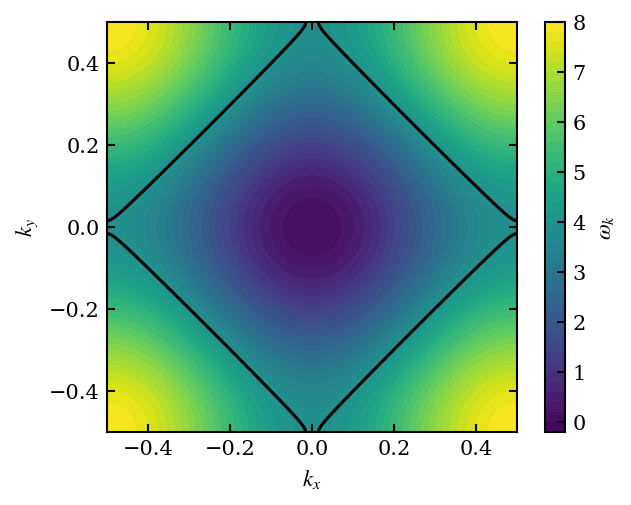

In [54]:
# --- Plotting ---
fig, ax = plt.subplots()

# Filled contour of band dispersion
c = ax.contourf(kx_grid, ky_grid, omega, levels=50, cmap="viridis")
fig.colorbar(c, ax=ax, label=r"$\omega_k$")

# Isofrequency contour at the emitter frequency
ax.contour(kx_grid, ky_grid, omega, levels=[detuning_freq], colors="black", linewidths=1.5)

ax.set_xlabel(r"$k_x$")
ax.set_ylabel(r"$k_y$")
ax.set_aspect("equal")

fig.tight_layout()
fig.savefig("./figures/isofrequency_contour_tb.png", dpi=300)

### Computation of the emitter exited state population as a function of time

In [6]:
lat = [[1, 0], [0, 1]]
orb = [[0, 0]]

band_index = 0  # index of the band to plot (0-based)

alpha = 0.067861
t1 = -0.017145
t2 = 0.00017919

alpha_norm = alpha/np.abs(t1)
t1_norm = t1/np.abs(t1)
t2_norm = t2/np.abs(t1)

infiniteModel = tb.tb_model(2, 2, lat, orb)

# onsite term
infiniteModel.set_onsite([alpha_norm])

# 1st nn
infiniteModel.set_hop(t1_norm, 0, 0, [1, 0])
infiniteModel.set_hop(t1_norm, 0, 0, [0, 1])

# 2nd nn
infiniteModel.set_hop(t2_norm, 0, 0, [1, 1])
infiniteModel.set_hop(t2_norm, 0, 0, [1, -1])

In [7]:
# load the data from a file
data_fields = mf.load("./data/Nk64/MPB_output.pkl")
Ex = data["Ex"]
Ey = data["Ey"]
Ez = data["Ez"]
kpts = data["kpts"]

detuning_freq = mf.load("./data/detuning_freq.pkl")

# .. Select the dipole moment
theta_90 = (90) * np.pi / 180
dipole_moment_90 = np.array([np.cos(theta_90), np.sin(theta_90), 0])

theta_135 = (135) * np.pi / 180
dipole_moment_135 = np.array([np.cos(theta_135), np.sin(theta_135), 0])

# .. Define the fields of the selected band
E_band = [Ex[band_index, :, :], Ey[band_index, :, :], Ez[band_index, :, :]]

In [8]:
# %% Finite model definition
N_cells = 41

# Cut the system
temporalModel = infiniteModel.cut_piece(
    N_cells, fin_dir=0, glue_edgs=False
)  # cutout along 1st direction
finiteModel = temporalModel.cut_piece(
    N_cells, fin_dir=1, glue_edgs=False
)  # cutout along 2nd direction

In [9]:
# Let me recalculate the coupling accordingly with the system's size (N_cells = 41).
# NOTE: the indexing is now "xy" so that the ordering of rjpts coincides with the one created by pythonTB

xjg = np.arange(-20,20 + 1, 1)
yjg = np.arange(-20,20 + 1, 1)
rjpts = mf.meshgrid_points(xjg, yjg, indexing="xy")

gr0rj_90 = mf.compute_gr0r(E_band, dipole_moment_90, detuning_freq, kpts, rjpts)
gr0rj_90_norm = gr0rj_90 * np.abs(t1)  # normalize to |t1|
gr0rj_135 = mf.compute_gr0r(E_band, dipole_moment_135, detuning_freq, kpts, rjpts)
gr0rj_135_norm = gr0rj_135 * np.abs(t1)  # normalize to |t1|
# TODO: check normalization here, does it make sense?

In [10]:
# %% Build the light-matter Hamiltonian

# ... non-local couplings
values_90 = gr0rj_90_norm[band_index, :]
values_135 = gr0rj_135_norm[band_index, :]

# small check before proceeding
assert len(values_90) == len(values_135), "Unexpected different lengths for the couplings!"

indexes = np.arange(0, len(gr0rj_90[0, :]), 1)
couplings_90 = [[list(values_90), list(indexes)]]
couplings_135 = [[list(values_135), list(indexes)]]

# build the light-matter Hamiltonian
H_total_90 = mf.make_light_matter_Hamiltonian(finiteModel, detuning_freq, couplings_90)
H_total_135 = mf.make_light_matter_Hamiltonian(finiteModel, detuning_freq, couplings_135)

In [11]:
# %% Compute time evolution

from scipy.sparse.linalg import expm_multiply

#
t0 = 0
tf = 20
t_steps = 100 + 1

tvals = np.linspace(t0, tf, t_steps)

# Define initial condition
assert np.shape(H_total_90) == np.shape(H_total_135), "Unexpected different shapes for the Hamiltonians!"
psi0 = np.zeros(np.shape(H_total_90)[0])
psi0[0] = 1

# Compute time evolution
psit_90 = expm_multiply(-1j * H_total_90, psi0, t0, tf, t_steps, endpoint=True)
psit_135 = expm_multiply(-1j * H_total_135, psi0, t0, tf, t_steps, endpoint=True)

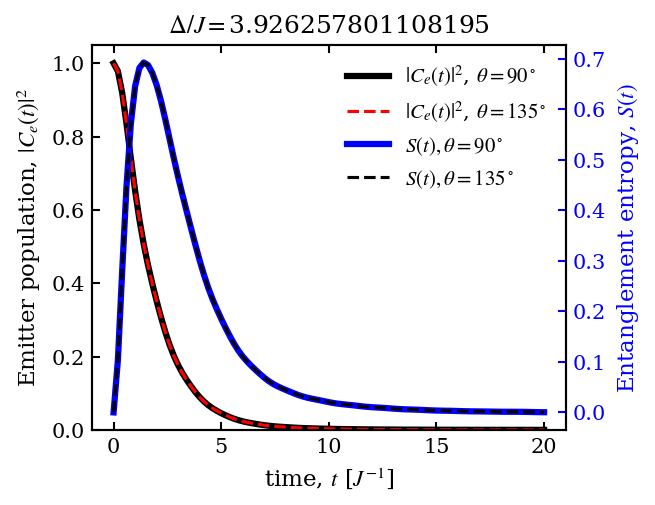

In [12]:
# %% Plot emitter's dynamics

# Prepare data to be plotted ...

# get emitter component of the overall wavefunction
mod_Ce_squared_90 = np.abs(psit_90[:, 0]) ** 2
mod_Ce_squared_135 = np.abs(psit_135[:, 0]) ** 2

# compute the entanglement for both cases
S_90 = mf.binary_entropy(mod_Ce_squared_90)
S_135 = mf.binary_entropy(mod_Ce_squared_135)

# --- plotting ---
fig, ax1 = plt.subplots()

# left y-axis: population
l1, = ax1.plot(tvals, mod_Ce_squared_90, lw=3, c="k", label=r"$|C_e(t)|^2$, $\theta=90^\circ$")
l2, = ax1.plot(tvals, mod_Ce_squared_135, c="r", ls="--", label=r"$|C_e(t)|^2$, $\theta=135^\circ$")
ax1.set_xlabel(r"time, $t$ [$J^{-1}$]")
ax1.set_ylabel(r"Emitter population, $|C_e(t)|^2$")
ax1.set_ylim([0, 1.05])

# right y-axis: entropy
ax2 = ax1.twinx()
l3, = ax2.plot(tvals, S_90, c="b", lw=3, label=r"$S(t), \theta=90^\circ$")
l4, = ax2.plot(tvals, S_135, c="k", ls="--", label=r"$S(t), \theta=135^\circ$")
ax2.set_ylabel(r"Entanglement entropy, $S(t)$", color="b")
ax2.tick_params(axis="y", colors="b")

# combine legends
lines = [l1, l2, l3, l4]
labels = [line.get_label() for line in lines]
ax1.legend(lines, labels, loc="best")

# title
ax1.set_title(r"$\Delta/J = $" + str(detuning_freq))

fig.tight_layout()
fig.savefig("./figures/emitter_dynamics_tb.png", dpi=300)

#### Spatial photon radiation patterns obtained for the two dipole orientations

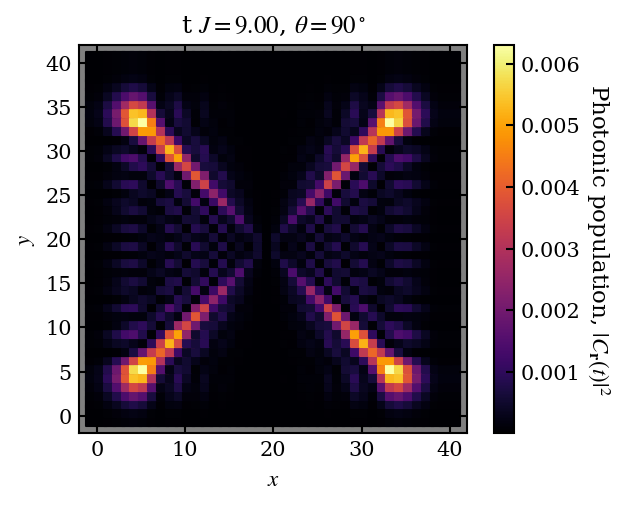

In [14]:
# %% Plot bath dynamics

time_index = 45

# Prepare data to be plotted ...

# get positions in Cartesian coordinates (requires find_positions() defined above)
positions = mf.find_positions(finiteModel._orb, finiteModel._lat)

# get photonic component of the overal wavefunction at selected time, i.e, tvals[time_index]
mod_Cr_squared_90 = np.abs(psit_90[time_index, 1 : np.shape(psit_90)[1]]) ** 2
mod_Cr_squared_135 = np.abs(psit_135[time_index, 1 : np.shape(psit_135)[1]]) ** 2

x = positions[:, 0]
y = positions[:, 1]
z1 = mod_Cr_squared_90
z2 = mod_Cr_squared_135

# Plot figure ...
fig, ax = plt.subplots()

cm = plt.get_cmap("inferno")

# scatter plot
sc = plt.scatter(x, y, c=z1, s=100, marker="s", cmap=cm)

# axis properties
ax.set(xlabel=r"$x$", ylabel=r"$y$", title=r"t $J= %.2f$" % tvals[time_index] + ", " + r"$\theta=90^\circ$")
ax.set_facecolor("gray")
ax.set_aspect("equal")

# colorbar
cbar = plt.colorbar(sc)
cbar.set_label(r"Photonic population, $|C_\mathbf{r}(t)|^2$", rotation=270, labelpad=15)

fig.tight_layout()
fig.savefig("./figures/bath_dynamics_tb_90.png", dpi=300)

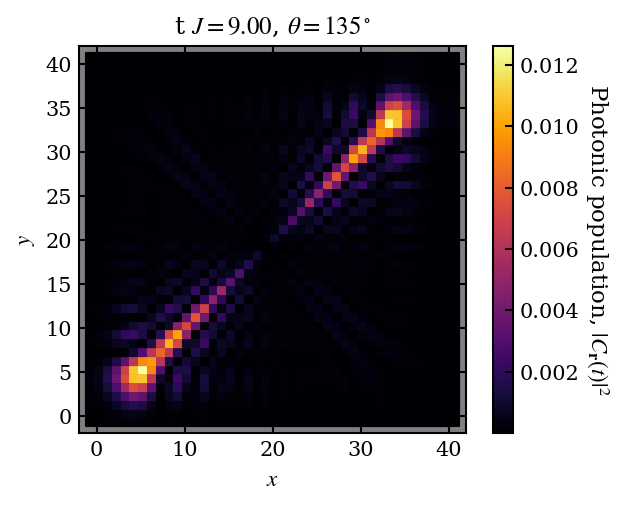

In [15]:
# Plot figure ...
fig, ax = plt.subplots()

cm = plt.get_cmap("inferno")

# scatter plot
sc = plt.scatter(x, y, c=z2, s=100, marker="s", cmap=cm)

# axis properties
ax.set(xlabel=r"$x$", ylabel=r"$y$", title=r"t $J= %.2f$" % tvals[time_index] + ", " + r"$\theta=135^\circ$")
ax.set_facecolor("gray")
ax.set_aspect("equal")

# colorbar
cbar = plt.colorbar(sc)
cbar.set_label(r"Photonic population, $|C_\mathbf{r}(t)|^2$", rotation=270, labelpad=15)

fig.tight_layout()
fig.savefig("./figures/bath_dynamics_tb_135.png", dpi=300)

In [21]:
import importlib
importlib.reload(mf)

<module 'myfunctions_v1' from '/home/antonio/phd/QuantumEmitters/kimble/myfunctions_v1.py'>